In [3]:

import pandas as pd
import numpy as np

# Load the original dataset
df = pd.read_csv('dirty_cafe_sales.csv')

# Check original dataset
print("Original dataset shape:", df.shape)
print(df.head())
df.info()

# Replace invalid placeholder values with NaN
df.replace(['ERROR', 'UNKNOWN'], np.nan, inplace=True)

# Convert numerical columns
numeric_columns = ['Quantity', 'Price Per Unit', 'Total Spent']

for col in numeric_columns:
    df[col] = pd.to_numeric(df[col], errors='coerce')

# Check missing values before removing rows
print("\nMissing values before cleaning:")
print(df.isnull().sum())

# Record original number of rows
original_rows = len(df)

# Remove rows missing essential numerical information
df = df.dropna(subset=numeric_columns).copy()

# Check how many rows were removed
removed_rows = original_rows - len(df)

print("\nRows removed:", removed_rows)
print("Remaining rows:", len(df))
print("Cleaned dataset shape:", df.shape)

# Verify cleaning
print("\nMissing values after cleaning:")
print(df[numeric_columns].isnull().sum())


Original dataset shape: (10000, 8)
  Transaction ID    Item Quantity Price Per Unit Total Spent  Payment Method  \
0    TXN_1961373  Coffee        2            2.0         4.0     Credit Card   
1    TXN_4977031    Cake        4            3.0        12.0            Cash   
2    TXN_4271903  Cookie        4            1.0       ERROR     Credit Card   
3    TXN_7034554   Salad        2            5.0        10.0         UNKNOWN   
4    TXN_3160411  Coffee        2            2.0         4.0  Digital Wallet   

   Location Transaction Date  
0  Takeaway       2023-09-08  
1  In-store       2023-05-16  
2  In-store       2023-07-19  
3   UNKNOWN       2023-04-27  
4  In-store       2023-06-11  
<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   Transaction ID    10000 non-null  str  
 1   Item              9667 non-null   str  
 2   Quantity         

In [4]:

# Calculate expected spending
df['Expected Total'] = df['Quantity'] * df['Price Per Unit']

# Identify discrepancies
df['Spending Difference'] = (
    df['Total Spent'] - df['Expected Total']
)

# Display inconsistent records
inconsistent = df[
    ~np.isclose(
        df['Total Spent'],
        df['Expected Total'],
        atol=0.01
    )
]

print("Inconsistent records:", len(inconsistent))
display(inconsistent.head(10))


Inconsistent records: 0


,Transaction ID,Item,Quantity,Price Per Unit,Total Spent,Payment Method,Location,Transaction Date,Expected Total,Spending Difference


In [5]:
print("Cleaned dataset overview:")
print(df.shape)

print("\nMissing values:")
print(df.isnull().sum())

print("\nNumerical summary:")
display(df.describe())

print("\nUnique menu items:")
print(df['Item'].value_counts())

Cleaned dataset overview:
(8544, 10)

Missing values:
Transaction ID            0
Item                    812
Quantity                  0
Price Per Unit            0
Total Spent               0
Payment Method         2691
Location               3373
Transaction Date        385
Expected Total            0
Spending Difference       0
dtype: int64

Numerical summary:


,Quantity,Price Per Unit,Total Spent,Expected Total,Spending Difference
count,8544.000000,8544.000000,8544.000000,8544.000000,8544.0
mean,3.022589,2.949438,8.929073,8.929073,0.0
std,1.419033,1.277886,5.999898,5.999898,0.0
min,1.000000,1.000000,1.000000,1.000000,0.0
25%,2.000000,2.000000,4.000000,4.000000,0.0
50%,3.000000,3.000000,8.000000,8.000000,0.0
75%,4.000000,4.000000,12.000000,12.000000,0.0
max,5.000000,5.000000,25.000000,25.000000,0.0



Unique menu items:
Item
Juice       1011
Coffee      1004
Cake         993
Salad        981
Sandwich     964
Tea          928
Smoothie     927
Cookie       924
Name: count, dtype: int64


In [6]:
eda_df = df.dropna(subset=['Item']).copy()

print("Original dataset:", df.shape)
print("EDA dataset:", eda_df.shape)

print("\nMissing values:")
print(eda_df.isnull().sum())


Original dataset: (8544, 10)
EDA dataset: (7732, 10)

Missing values:
Transaction ID            0
Item                      0
Quantity                  0
Price Per Unit            0
Total Spent               0
Payment Method         2441
Location               3061
Transaction Date        350
Expected Total            0
Spending Difference       0
dtype: int64


Item
Juice       1011
Coffee      1004
Cake         993
Salad        981
Sandwich     964
Tea          928
Smoothie     927
Cookie       924
Name: count, dtype: int64
Graph saved as cafe_item_distribution.png


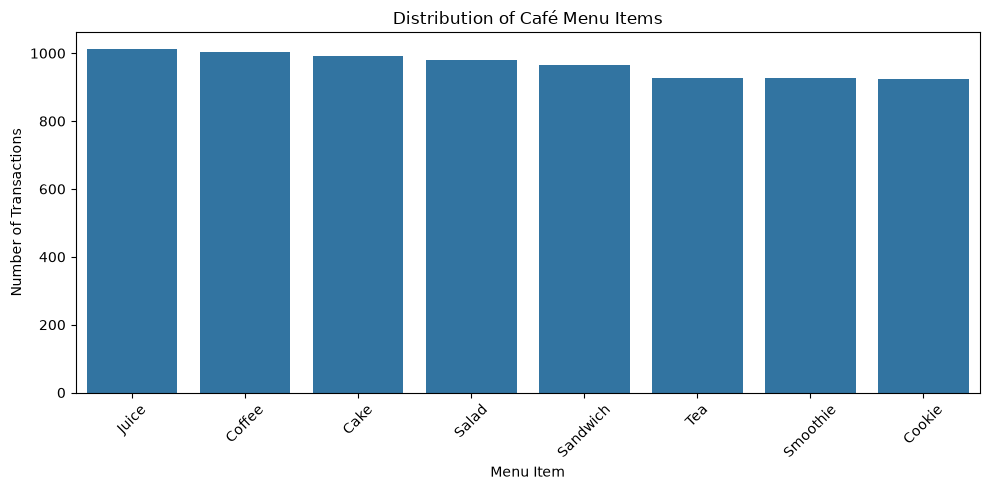

In [7]:

# Count the number of transactions for each item
item_counts = eda_df['Item'].value_counts()

print(item_counts)

# Visualize the distribution
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 5))

sns.countplot(
    data=eda_df,
    x='Item',
    order=item_counts.index
)

plt.title('Distribution of Café Menu Items')
plt.xlabel('Menu Item')
plt.ylabel('Number of Transactions')
plt.xticks(rotation=45)

plt.tight_layout()

plt.savefig('cafe_item_distribution.png', dpi=300)
print("Graph saved as cafe_item_distribution.png")
plt.show()


In [8]:
# Summary statistics for numerical columns
numeric_columns = [
    'Quantity',
    'Price Per Unit',
    'Total Spent'
]

display(eda_df[numeric_columns].describe())


,Quantity,Price Per Unit,Total Spent
count,7732.000000,7732.000000,7732.000000
mean,3.024056,2.949431,8.931842
std,1.420944,1.275787,5.998519
min,1.000000,1.000000,1.000000
25%,2.000000,2.000000,4.000000
50%,3.000000,3.000000,8.000000
75%,4.000000,4.000000,12.000000
max,5.000000,5.000000,25.000000


Graph saved as cafe_numerical_distributions.png


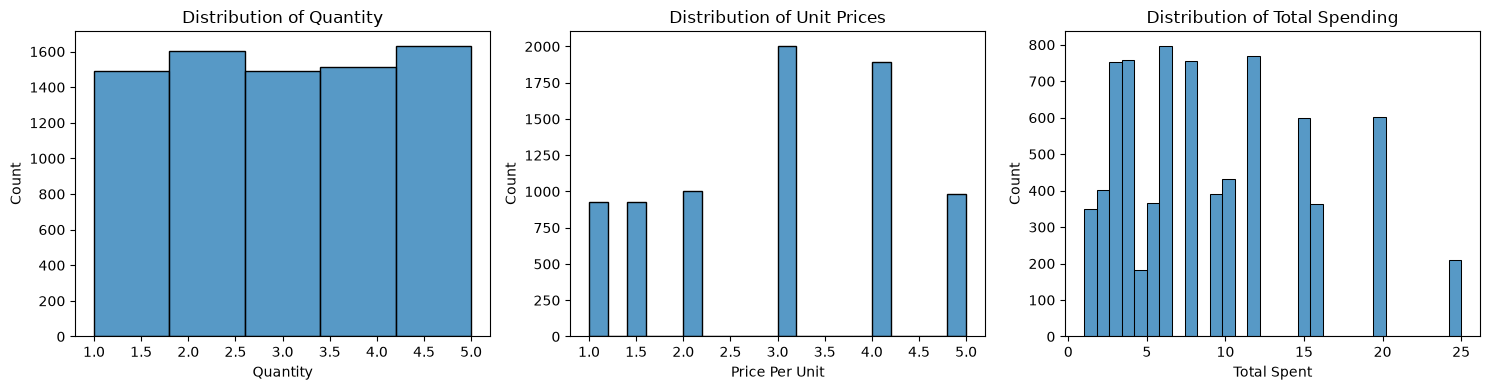

In [9]:

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

sns.histplot(
    data=eda_df,
    x='Quantity',
    bins=5,
    ax=axes[0]
)
axes[0].set_title('Distribution of Quantity')

sns.histplot(
    data=eda_df,
    x='Price Per Unit',
    ax=axes[1]
)
axes[1].set_title('Distribution of Unit Prices')

sns.histplot(
    data=eda_df,
    x='Total Spent',
    ax=axes[2]
)
axes[2].set_title('Distribution of Total Spending')

plt.tight_layout()

plt.savefig('cafe_numerical_distributions.png', dpi=300)
print("Graph saved as cafe_numerical_distributions.png")
plt.show()



In [10]:
price_summary = (
    eda_df.groupby('Item')['Price Per Unit']
    .agg(['mean', 'min', 'max', 'count'])
    .sort_values('mean')
)

display(price_summary)


,mean,min,max,count
Item,,,,
Cookie,1.0,1.0,1.0,924
Tea,1.5,1.5,1.5,928
Coffee,2.0,2.0,2.0,1004
Cake,3.0,3.0,3.0,993
Juice,3.0,3.0,3.0,1011
Sandwich,4.0,4.0,4.0,964
Smoothie,4.0,4.0,4.0,927
Salad,5.0,5.0,5.0,981


Graph saved as cafe_categorical_distributions.png


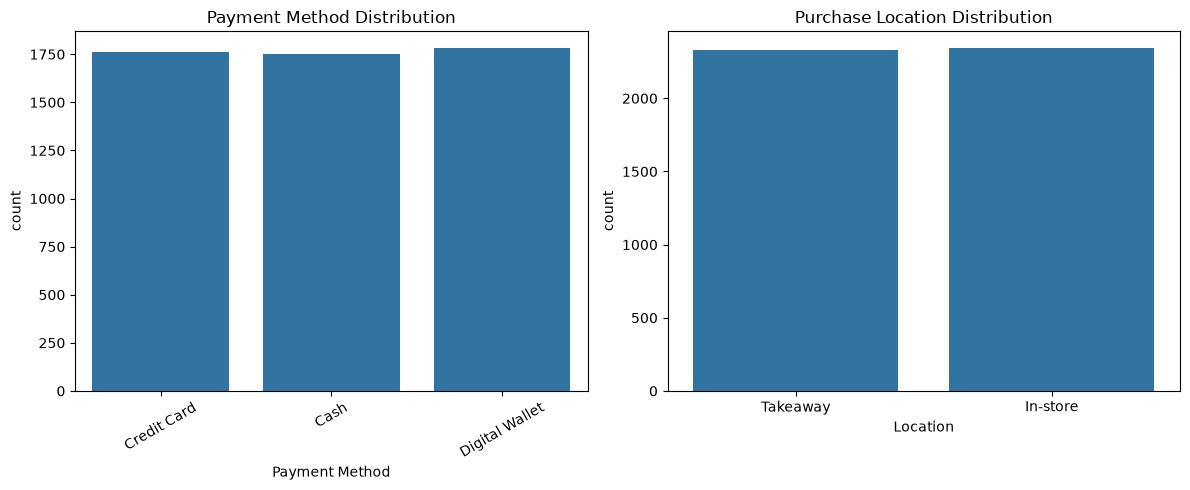

In [11]:

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.countplot(
    data=eda_df,
    x='Payment Method',
    ax=axes[0]
)

axes[0].set_title('Payment Method Distribution')
axes[0].tick_params(axis='x', rotation=30)

sns.countplot(
    data=eda_df,
    x='Location',
    ax=axes[1]
)

axes[1].set_title('Purchase Location Distribution')

plt.tight_layout()

plt.savefig('cafe_categorical_distributions.png', dpi=300)
print("Graph saved as cafe_categorical_distributions.png")
plt.show()


Graph saved as cafe_temporal_distributions.png


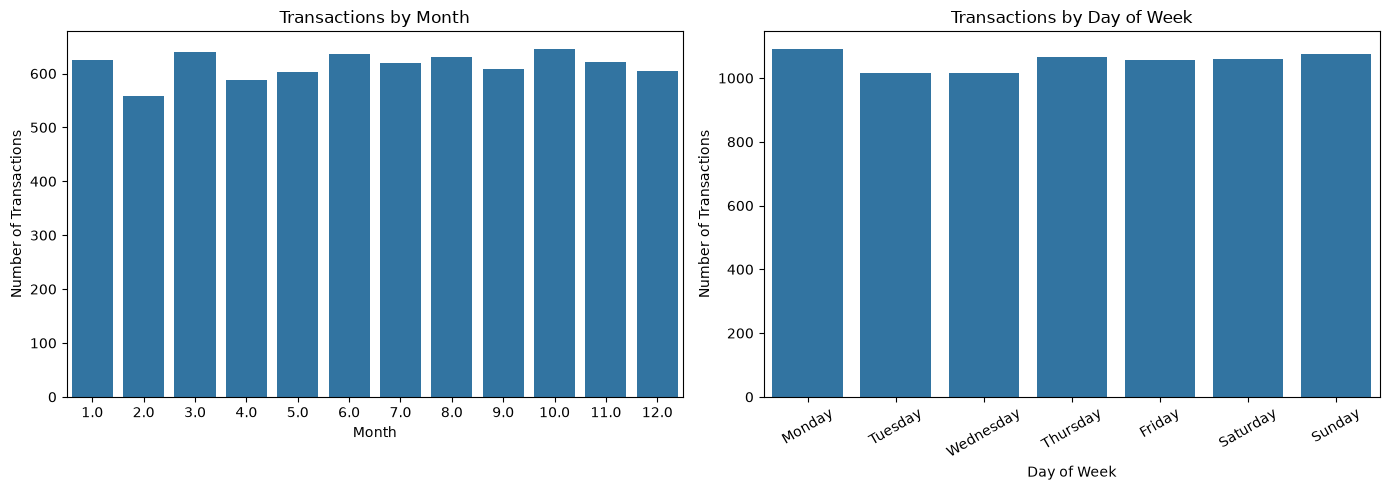

In [12]:
# Convert transaction dates
eda_df['Transaction Date'] = pd.to_datetime(eda_df['Transaction Date'], errors='coerce')

# Extract month and day of week
eda_df['Month'] = eda_df['Transaction Date'].dt.month
eda_df['Day of Week'] = eda_df['Transaction Date'].dt.day_name()

# Plot temporal distributions
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.countplot(data=eda_df, x='Month', ax=axes[0])
axes[0].set_title('Transactions by Month')
axes[0].set_xlabel('Month')
axes[0].set_ylabel('Number of Transactions')

day_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
sns.countplot(data=eda_df, x='Day of Week', order=day_order, ax=axes[1])
axes[1].set_title('Transactions by Day of Week')
axes[1].set_xlabel('Day of Week')
axes[1].set_ylabel('Number of Transactions')
axes[1].tick_params(axis='x', rotation=30)

plt.tight_layout()


plt.savefig('cafe_temporal_distributions.png', dpi=300)
print("Graph saved as cafe_temporal_distributions.png")


plt.show()

In [13]:

# Check how many transactions have missing dates
print(
    "Transactions with missing dates:",
    eda_df['Transaction Date'].isna().sum()
)

# Keep transactions with valid dates
daily_df = eda_df.dropna(subset=['Transaction Date']).copy()

# Group transactions by date and menu item
daily_item_sales = (
    daily_df
    .groupby(['Transaction Date', 'Item'])
    .agg(
        Daily_Revenue=('Total Spent', 'sum'),
        Daily_Quantity_Sold=('Quantity', 'sum'),
        Transaction_Count=('Transaction ID', 'count'),
        Average_Unit_Price=('Price Per Unit', 'mean')
    )
    .reset_index()
)

# Display the daily sales dataset
print("Original transactions with valid dates:", len(daily_df))
print("Daily item records:", len(daily_item_sales))

display(daily_item_sales.head(10))


Transactions with missing dates: 350
Original transactions with valid dates: 7382
Daily item records: 2712


,Transaction Date,Item,Daily_Revenue,Daily_Quantity_Sold,Transaction_Count,Average_Unit_Price
0,2023-01-01,Cake,21.0,7.0,2,3.0
1,2023-01-01,Coffee,26.0,13.0,4,2.0
2,2023-01-01,Cookie,4.0,4.0,1,1.0
3,2023-01-01,Juice,18.0,6.0,2,3.0
4,2023-01-01,Salad,10.0,2.0,1,5.0
5,2023-01-01,Sandwich,24.0,6.0,2,4.0
6,2023-01-01,Smoothie,8.0,2.0,1,4.0
7,2023-01-01,Tea,4.5,3.0,1,1.5
8,2023-01-02,Cake,21.0,7.0,3,3.0
9,2023-01-02,Coffee,6.0,3.0,1,2.0


In [2]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# 1. Load & clean base data (in case earlier cells haven't been executed yet)
df = pd.read_csv('dirty_cafe_sales.csv')
df.replace(['ERROR', 'UNKNOWN'], np.nan, inplace=True)

for col in ['Quantity', 'Price Per Unit', 'Total Spent']:
    df[col] = pd.to_numeric(df[col], errors='coerce')

df = df.dropna(subset=['Quantity', 'Price Per Unit', 'Total Spent', 'Item']).copy()
df['dt'] = pd.to_datetime(df['Transaction Date'], errors='coerce')
df['day_of_week'] = df['dt'].dt.day_name().fillna('Unknown')
df['month'] = df['dt'].dt.month.fillna(0).astype(int)
df['Location_clean'] = df['Location'].fillna('Unknown')
df['Payment_clean'] = df['Payment Method'].fillna('Unknown')

# 2. Aggregate to Item x Date (daily item performance) where dates are valid
daily_df = (
    df.dropna(subset=['dt'])
    .groupby(['dt', 'Item'], as_index=False)
    .agg(
        daily_revenue=('Total Spent', 'sum'),
        txn_count=('Transaction ID', 'count'),
        price_per_unit=('Price Per Unit', 'first'),
        day_of_week=('day_of_week', 'first'),
        month=('month', 'first'),
        top_location=('Location_clean', lambda s: s.mode()[0] if len(s.mode()) > 0 else 'Unknown'),
        top_payment=('Payment_clean', lambda s: s.mode()[0] if len(s.mode()) > 0 else 'Unknown'),
    )
)

# Label: 1 if item's daily revenue is below median daily item revenue (potentially underperforming day)
rev_median = daily_df['daily_revenue'].median()
daily_df['underperforming_day'] = (daily_df['daily_revenue'] < rev_median).astype(int)

# 3. Features (item & context characteristics; no daily_revenue or txn_count leakage)
feature_cols = ['Item', 'price_per_unit', 'day_of_week', 'month', 'top_location', 'top_payment']
X = daily_df[feature_cols]
y = daily_df['underperforming_day']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore'), ['Item', 'day_of_week', 'top_location', 'top_payment']),
        ('num', 'passthrough', ['price_per_unit', 'month']),
    ]
)

clf = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', RandomForestClassifier(n_estimators=200, random_state=42))
])

clf.fit(X_train, y_train)
y_pred = clf.predict(X_test)
y_prob = clf.predict_proba(X_test)[:, 1]

print(f"Daily item revenue median benchmark: ${rev_median:.2f}")
print(f"Test Accuracy: {accuracy_score(y_test, y_pred):.4f}\n")
print(classification_report(y_test, y_pred, target_names=['Strong/Normal (0)', 'Underperforming (1)']))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))

# 4. Inspect 5 misclassified item-day samples
errors = X_test.copy()
errors['date'] = daily_df.loc[X_test.index, 'dt'].dt.strftime('%Y-%m-%d')
errors['daily_revenue'] = daily_df.loc[X_test.index, 'daily_revenue']
errors['txn_count'] = daily_df.loc[X_test.index, 'txn_count']
errors['actual_underperf'] = y_test
errors['pred_underperf'] = y_pred
errors['prob_underperf'] = y_prob.round(3)

misclassified = errors[errors['actual_underperf'] != errors['pred_underperf']]
print(f"\nTotal misclassified test rows: {len(misclassified)}")
display(misclassified.head(5))

Daily item revenue median benchmark: $20.00
Test Accuracy: 0.6630

                     precision    recall  f1-score   support

  Strong/Normal (0)       0.65      0.71      0.68       273
Underperforming (1)       0.68      0.61      0.64       270

           accuracy                           0.66       543
          macro avg       0.66      0.66      0.66       543
       weighted avg       0.66      0.66      0.66       543

Confusion Matrix:
 [[194  79]
 [104 166]]

Total misclassified test rows: 183


,Item,price_per_unit,day_of_week,month,top_location,top_payment,date,daily_revenue,txn_count,actual_underperf,pred_underperf,prob_underperf
544,Juice,3.0,Wednesday,3,In-store,Digital Wallet,2023-03-15,30.0,4,0,1,0.699
2511,Tea,1.5,Monday,12,Takeaway,Cash,2023-12-04,7.5,3,1,0,0.315
1833,Juice,3.0,Monday,9,In-store,Unknown,2023-09-04,9.0,1,1,0,0.355
2354,Coffee,2.0,Tuesday,11,Unknown,Cash,2023-11-14,36.0,5,0,1,0.815
1753,Salad,5.0,Thursday,8,Unknown,Cash,2023-08-24,15.0,2,1,0,0.015


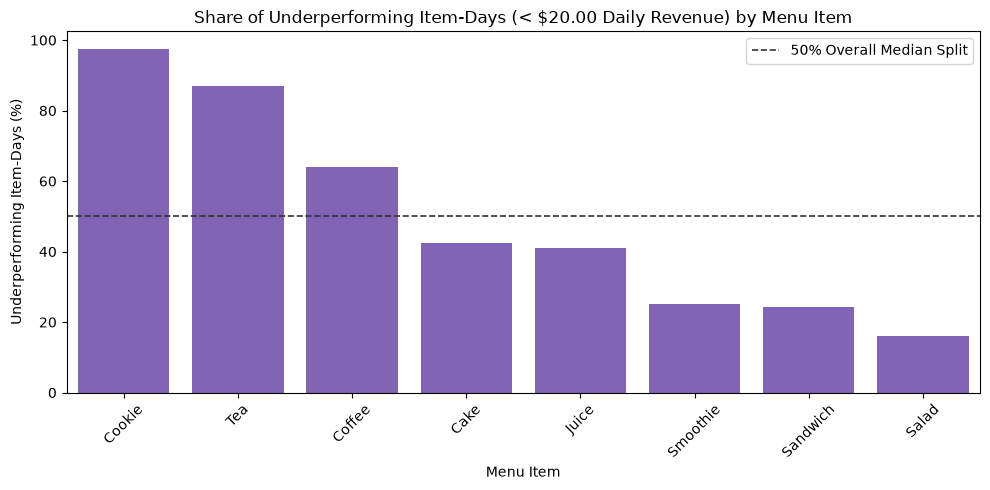

In [3]:
import matplotlib.pyplot as plt
import seaborn as sns

# Share of item-days below the $20.00 median benchmark by menu item
perf_by_item = (
    daily_df.groupby('Item', as_index=False)
    .agg(
        underperf_rate=('underperforming_day', 'mean'),
        avg_daily_rev=('daily_revenue', 'mean'),
        days_count=('underperforming_day', 'count')
    )
    .sort_values('underperf_rate', ascending=False)
)
perf_by_item['underperf_pct'] = perf_by_item['underperf_rate'] * 100

plt.figure(figsize=(10, 5))
sns.barplot(data=perf_by_item, x='Item', y='underperf_pct', color='#7E57C2')
plt.axhline(50, color='#333333', linestyle='--', linewidth=1.2, label='50% Overall Median Split')
plt.title('Share of Underperforming Item-Days (< $20.00 Daily Revenue) by Menu Item')
plt.xlabel('Menu Item')
plt.ylabel('Underperforming Item-Days (%)')
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.savefig('cafe_underperforming_items.png', dpi=300)
plt.show()

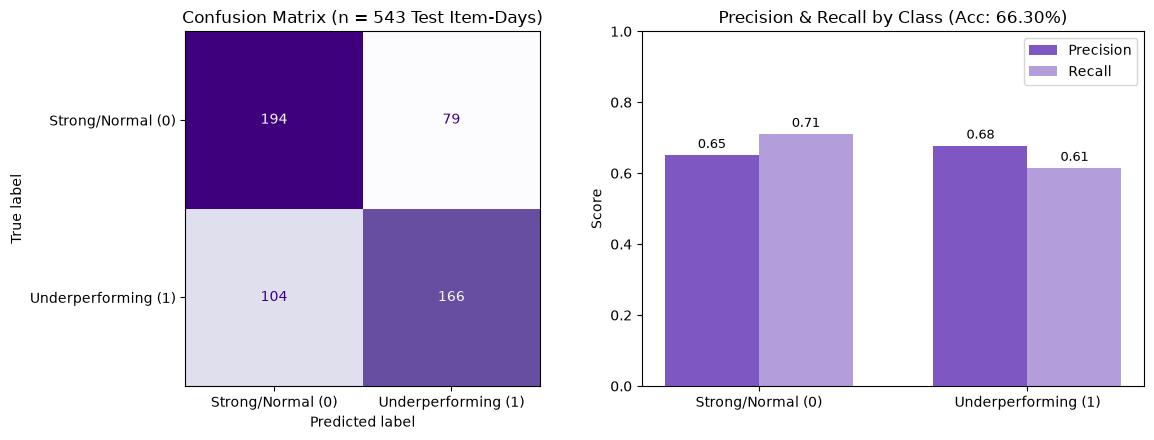

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import ConfusionMatrixDisplay, precision_recall_fscore_support

cm = confusion_matrix(y_test, y_pred)
prec, rec, f1, _ = precision_recall_fscore_support(
    y_test, y_pred, labels=[0, 1], zero_division=0
)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# Left subplot: Confusion Matrix
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['Strong/Normal (0)', 'Underperforming (1)']
)
disp.plot(ax=axes[0], cmap='Purples', colorbar=False)
axes[0].set_title('Confusion Matrix (n = 543 Test Item-Days)')

# Right subplot: Precision & Recall by Class
classes = ['Strong/Normal (0)', 'Underperforming (1)']
x = np.arange(len(classes))
width = 0.35

axes[1].bar(x - width / 2, prec, width, label='Precision', color='#7E57C2')
axes[1].bar(x + width / 2, rec, width, label='Recall', color='#B39DDB')
axes[1].set_ylim(0, 1.0)
axes[1].set_xticks(x)
axes[1].set_xticklabels(classes)
axes[1].set_ylabel('Score')
axes[1].set_title('Precision & Recall by Class (Acc: 66.30%)')
axes[1].legend()

for i, (p, r) in enumerate(zip(prec, rec)):
    axes[1].text(i - width / 2, p + 0.02, f'{p:.2f}', ha='center', fontsize=9)
    axes[1].text(i + width / 2, r + 0.02, f'{r:.2f}', ha='center', fontsize=9)

plt.tight_layout()
plt.savefig('cafe_model_evaluation.png', dpi=300)
plt.show()

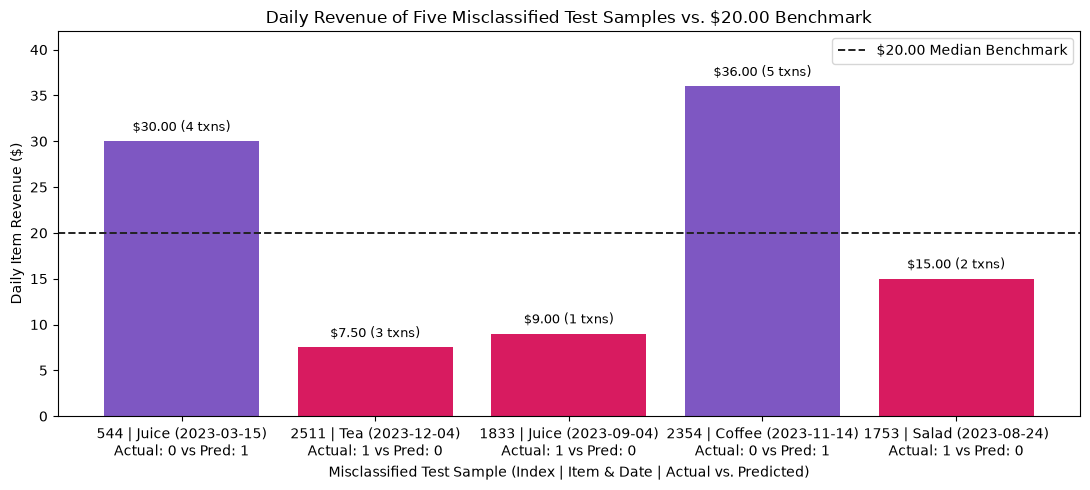

In [5]:
import matplotlib.pyplot as plt

# Rows from your 5 misclassified test samples: 544, 2511, 1833, 2354, 1753
sample_ids = [544, 2511, 1833, 2354, 1753]
err_5 = errors.loc[sample_ids].copy()
err_5['label'] = [
    f"{idx} | {row['Item']} ({row['date']})\nActual: {row['actual_underperf']} vs Pred: {row['pred_underperf']}"
    for idx, row in err_5.iterrows()
]

colors = ['#7E57C2' if a == 0 else '#D81B60' for a in err_5['actual_underperf']]

plt.figure(figsize=(11, 5))
bars = plt.bar(err_5['label'], err_5['daily_revenue'], color=colors)
plt.axhline(20.0, color='#222222', linestyle='--', linewidth=1.4, label='$20.00 Median Benchmark')

for bar, (_, row) in zip(bars, err_5.iterrows()):
    h = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        h + 0.8,
        f"${h:.2f} ({int(row['txn_count'])} txns)",
        ha='center',
        va='bottom',
        fontsize=9
    )

plt.title('Daily Revenue of Five Misclassified Test Samples vs. $20.00 Benchmark')
plt.ylabel('Daily Item Revenue ($)')
plt.xlabel('Misclassified Test Sample (Index | Item & Date | Actual vs. Predicted)')
plt.ylim(0, max(err_5['daily_revenue'].max(), 20.0) + 6)
plt.legend()
plt.tight_layout()
plt.savefig('cafe_misclassified_samples.png', dpi=300)
plt.show()

In [10]:
  
git status
git add MediumPost_module5.ipynb cafe_*.png
git commit -m "Add Module 5 supervised learning notebook and figures"
git push origin main

SyntaxError: invalid syntax (959132079.py, line 1)